In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("placement.csv")
df.head()

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0


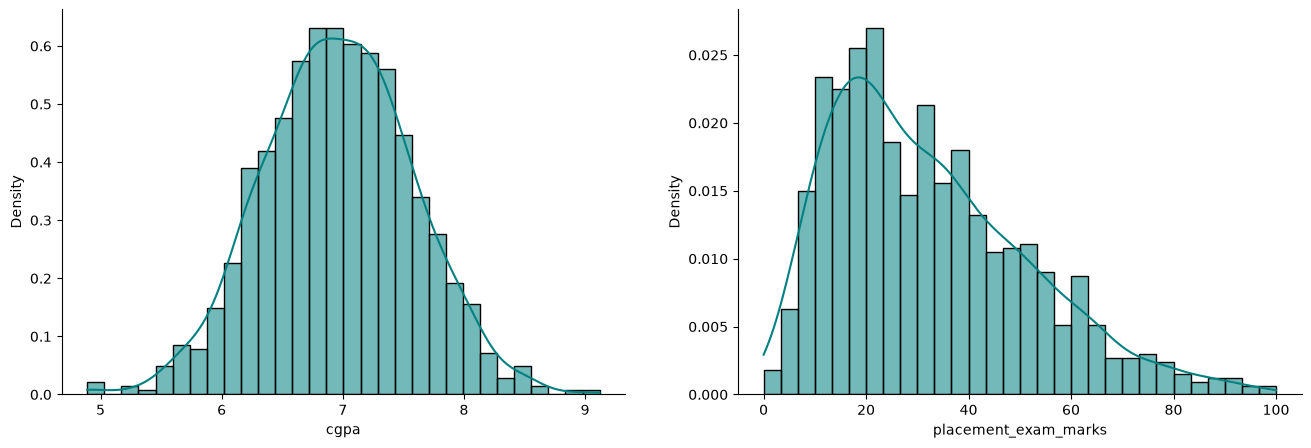

In [4]:
plt.figure(figsize=(16,5))
plt.subplot(1,2,1)
sns.histplot(df['cgpa'],kde=True,stat='density',color='teal',bins=30, alpha=0.55)

plt.subplot(1,2,2)
sns.histplot(df['placement_exam_marks'],kde=True,stat='density',color='teal',bins=30, alpha=0.55)

sns.despine()
plt.show()

In [5]:
print("highest allowed",df['cgpa'].mean()+3*df['cgpa'].std())
print("lowest allowed",df['cgpa'].mean()-3*df['cgpa'].std())

highest allowed 8.808933625397168
lowest allowed 5.113546374602832


In [6]:
df[(df['cgpa']>8.80)|(df['cgpa']<5.11)]

,cgpa,placement_exam_marks,placed
485,4.92,44.0,1
995,8.87,44.0,1
996,9.12,65.0,1
997,4.89,34.0,0
999,4.90,10.0,1


In [7]:
new_df = df[(df['cgpa']<8.80)&(df['cgpa']>5.11)]
new_df.head()

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0


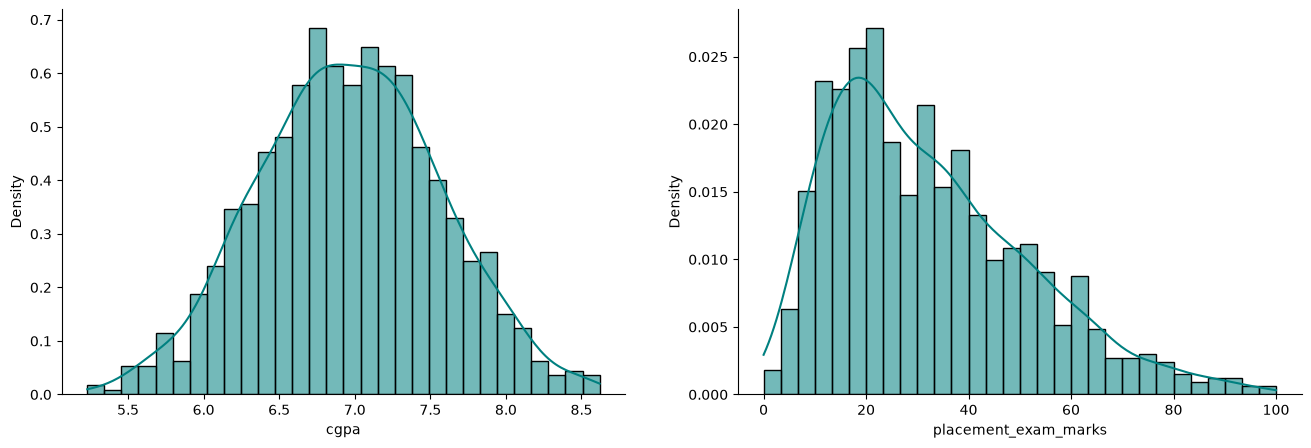

In [8]:
plt.figure(figsize=(16,5))
plt.subplot(1,2,1)
sns.histplot(new_df['cgpa'],kde=True,stat='density',color='teal',bins=30, alpha=0.55)

plt.subplot(1,2,2)
sns.histplot(new_df['placement_exam_marks'],kde=True,stat='density',color='teal',bins=30, alpha=0.55)

sns.despine()
plt.show()

In [9]:
upper_limit = df['cgpa'].mean()+3*df['cgpa'].std()
lower_limit = df['cgpa'].mean()-3*df['cgpa'].std()

In [10]:
upper_limit

np.float64(8.808933625397168)

In [11]:
df['cgpa'] = np.where(
    df['cgpa']>upper_limit,
    upper_limit,
    np.where(
        df['cgpa']<lower_limit,
        lower_limit,
        df['cgpa']
    )
)

In [12]:
df.shape

(1000, 3)

In [13]:
df['placement_exam_marks'].describe()

count    1000.000000
mean       32.225000
std        19.130822
min         0.000000
25%        17.000000
50%        28.000000
75%        44.000000
max       100.000000
Name: placement_exam_marks, dtype: float64

<Axes: ylabel='placement_exam_marks'>

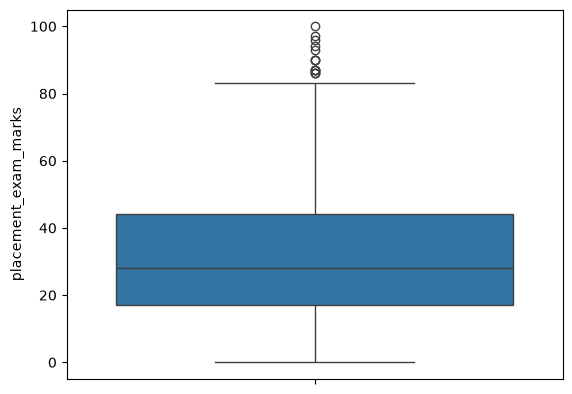

In [15]:
sns.boxplot(df['placement_exam_marks'])

In [16]:
percentile_25 = df['placement_exam_marks'].quantile(0.25)
percentile_75 = df['placement_exam_marks'].quantile(0.75)

In [18]:
percentile_25

np.float64(17.0)

In [20]:
iqr = percentile_75 - percentile_25

In [21]:
iqr

np.float64(27.0)

In [23]:
upper_limit = percentile_75 + 1.5*iqr
lower_limit = percentile_25 + 1.5*iqr

In [24]:
print("upper_limit",upper_limit)
print("lower_limit",lower_limit)

upper_limit 84.5
lower_limit 57.5


In [25]:
new_df = df[df['placement_exam_marks']<upper_limit]

In [27]:
new_df.shape

(985, 3)

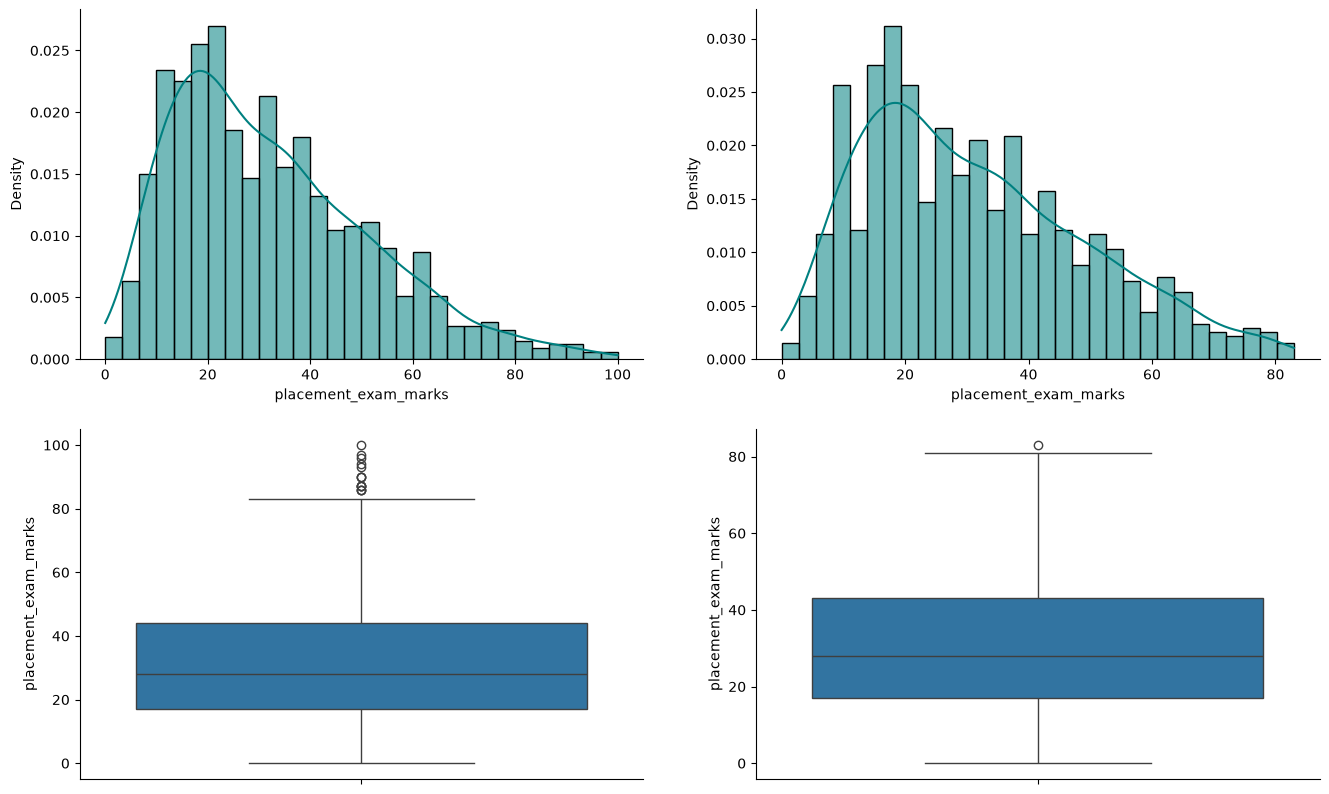

In [31]:
plt.figure(figsize=(16,10))
plt.subplot(2,2,1)
sns.histplot(df['placement_exam_marks'],kde=True,stat='density',color='teal',bins=30, alpha=0.55)

plt.subplot(2,2,2)
sns.histplot(new_df['placement_exam_marks'],kde=True,stat='density',color='teal',bins=30, alpha=0.55)

plt.subplot(2,2,3)
sns.boxplot(df['placement_exam_marks'])

plt.subplot(2,2,4)
sns.boxplot(new_df['placement_exam_marks'])


sns.despine()
plt.show()